Connect to Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Set paths, verify provided files and GPU, prepare the submission folder

In [2]:
import sys, shutil, json, time
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn.functional as F

BASE = Path("/content/drive/MyDrive/cv_bootcamp")      # provided files
SUB  = BASE / "submission"                              # what gets zipped
CODE, PRED = SUB / "code", SUB / "predictions"
WORK = BASE / "work"                                    # checkpoints and logs (not submitted)
for d in (CODE, PRED, WORK, CODE / "data"): d.mkdir(parents=True, exist_ok=True)

def find(name):
    """Find a provided file anywhere under BASE (skips submission/ and work/)."""
    hit = next((p for p in BASE.rglob(name) if not {"submission", "work"} & set(p.parts)), None)
    if hit is None: raise FileNotFoundError(name)
    return hit

for f in ["train_images.npy", "test_images.npy", "labels.csv", "train_idx.txt",
          "val_idx.txt", "classes.txt", "model.py", "check_format.py", "results_template.json"]:
    try: print("✅", find(f).relative_to(BASE))
    except FileNotFoundError: print("❌ MISSING:", f)

# Organizer's model and format checker go into code/ (needed for imports and for the submission)
for f in ["model.py", "check_format.py"]: shutil.copy2(find(f), CODE / f)
shutil.copy2(find("train_idx.txt"), CODE / "data" / "train_idx.txt")   # check_format.py reads data/train_idx.txt
sys.path.insert(0, str(CODE))

print("\nGPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "❌ NO GPU – enable it in Runtime settings")

✅ data/train_images.npy
✅ data/test_images.npy
✅ data/labels.csv
✅ data/train_idx.txt
✅ data/val_idx.txt
✅ data/classes.txt
✅ model.py
✅ check_format.py
✅ results_template.json

GPU: Tesla T4


Load data onto the GPU

In [3]:
from model import ResNet18

DEV = torch.device("cuda")
torch.backends.cudnn.benchmark = True
to_gpu = lambda f: torch.from_numpy(np.load(f)).permute(0, 3, 1, 2).contiguous().to(DEV)  # NHWC uint8 -> NCHW

X, X_TEST = to_gpu(find("train_images.npy")), to_gpu(find("test_images.npy"))
lab = pd.read_csv(find("labels.csv")).sort_values("index")
NOISY, SYNTH, CLEAN = (lab[c].to_numpy() for c in ["noisy_label", "synthetic_label", "clean_label"])
TRAIN_IDX = np.loadtxt(find("train_idx.txt"), dtype=np.int64)
VAL_IDX   = np.loadtxt(find("val_idx.txt"), dtype=np.int64)
CLASSES   = find("classes.txt").read_text().split()
print("train images", tuple(X.shape), "| test images", tuple(X_TEST.shape),
      "| train/val split", len(TRAIN_IDX), len(VAL_IDX))

train images (50000, 3, 32, 32) | test images (10000, 3, 32, 32) | train/val split 45000 5000


Training setup shared by every run
Same for all runs: ResNet-18 from scratch, SGD (lr 0.1, momentum 0.9, weight decay 5e-4), cosine schedule, 60 epochs, batch 128, seed 42, RandomCrop(32, padding 4) + horizontal flip. Images and augmentation stay on the GPU, with mixed precision, for speed.

In [4]:
MEAN = torch.tensor([0.4914, 0.4822, 0.4465], device=DEV).view(1, 3, 1, 1)
STD  = torch.tensor([0.2470, 0.2435, 0.2616], device=DEV).view(1, 3, 1, 1)
normalize = lambda x: (x.float() / 255 - MEAN) / STD

def augment(x):
    """RandomCrop(32, padding=4) + random horizontal flip for a uint8 batch, on the GPU."""
    n, ar = x.size(0), torch.arange(32, device=DEV)
    x = F.pad(x, (4, 4, 4, 4))
    rows = (torch.randint(0, 9, (n, 1), device=DEV) + ar)[:, None, :, None]
    cols = (torch.randint(0, 9, (n, 1), device=DEV) + ar)[:, None, None, :]
    x = x[torch.arange(n, device=DEV)[:, None, None, None], torch.arange(3, device=DEV)[None, :, None, None], rows, cols]
    return torch.where(torch.rand(n, device=DEV)[:, None, None, None] < 0.5, x.flip(3), x)

@torch.no_grad()
def predict_probs(model, x, tta=False, bs=1000):
    """Softmax probabilities for uint8 images; tta=True also averages the flipped image."""
    model.eval()
    out = []
    for b in x.split(bs):
        b = normalize(b)
        with torch.autocast("cuda", dtype=torch.float16):
            p = model(b).float().softmax(1)
            if tta: p = (p + model(b.flip(3)).float().softmax(1)) / 2
        out.append(p)
    return torch.cat(out).cpu().numpy()

def accuracy(model, idx, labels):
    return float((predict_probs(model, X[idx]).argmax(1) == labels[idx]).mean())

def load_model(path):
    m = ResNet18(num_classes=10).to(DEV)
    m.load_state_dict(torch.load(path, map_location=DEV))
    return m

def save_test_preds(model, filename):
    """Write test predictions in the required id,pred format."""
    pred = predict_probs(model, X_TEST).argmax(1)
    pd.DataFrame({"id": np.arange(len(pred)), "pred": pred}).to_csv(PRED / filename, index=False)

def ce_loss(logits, y, pos):
    return F.cross_entropy(logits.float(), y)

def train_run(name, idx, y, loss_fn=ce_loss, select_y=None, epoch_hook=None, epochs=60, bs=128, seed=42):
    """Train ResNet-18 from scratch on images X[idx] with labels y.
    Saves final.pt (last epoch) and, if select_y is given, best.pt (highest val accuracy against select_y).
    epoch_hook(model) can return extra per-epoch metrics to log. Skips training if the run already exists."""
    run = WORK / name
    if (run / "final.pt").exists():
        print(f"[{name}] already trained – loading saved history")
        return json.load(open(run / "history.json"))
    run.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(seed); np.random.seed(seed)
    model = ResNet18(num_classes=10).to(DEV).to(memory_format=torch.channels_last)
    opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler()
    x_tr, y_tr = X[torch.as_tensor(idx, device=DEV)], torch.as_tensor(y, device=DEV)
    history, best = [], -1.0

    for epoch in range(1, epochs + 1):
        t0, total = time.time(), 0.0
        model.train()
        for pos in torch.randperm(len(idx), device=DEV).split(bs):          # shuffled mini-batches
            xb = normalize(augment(x_tr[pos])).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = loss_fn(model(xb), y_tr[pos], pos)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            total += loss.item() * len(pos)
        sched.step()

        row = {"epoch": epoch, "loss": round(total / len(idx), 4)}
        if select_y is not None: row["val_acc"] = round(accuracy(model, VAL_IDX, select_y), 4)
        if epoch_hook: row.update(epoch_hook(model))
        history.append(row)
        print(f"[{name}] " + "  ".join(f"{k}={v}" for k, v in row.items()) + f"  ({time.time() - t0:.0f}s)", flush=True)
        if select_y is not None and row["val_acc"] > best:                 # keep best epoch for model selection
            best = row["val_acc"]; torch.save(model.state_dict(), run / "best.pt")

    torch.save(model.state_dict(), run / "final.pt")
    json.dump(history, open(run / "history.json", "w"))
    return history

Task 1 · Noise rate and 10×10 confusion matrix (training split; clean labels used for measurement only)

Noise rate on the training split: 0.4024 (18109 wrong labels)



,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
airplane,2925,293,314,89,94,105,85,75,379,146
automobile,191,2657,63,116,80,68,60,64,71,1126
bird,263,165,2842,212,254,216,222,147,106,77
cat,180,160,354,2168,194,924,206,106,91,86
deer,184,142,316,184,2195,491,174,683,94,50
dog,150,131,240,834,183,2620,123,136,55,61
frog,170,166,373,350,229,257,2676,124,96,62
horse,179,120,111,100,233,289,101,3246,77,50
ship,369,333,94,65,96,79,71,99,3076,214
truck,180,1247,81,87,78,81,52,68,115,2486


 wrong labels                 pair  share  cumulative
         2373 automobile <-> truck  0.131       0.131
         1758          cat <-> dog  0.097       0.228
          916       deer <-> horse  0.051       0.279
          748    airplane <-> ship  0.041       0.320
          674         deer <-> dog  0.037       0.357
          595        bird <-> frog  0.033       0.390

Noise rate per class: {'airplane': 0.351, 'automobile': 0.409, 'bird': 0.369, 'cat': 0.515, 'deer': 0.514, 'dog': 0.422, 'frog': 0.406, 'horse': 0.28, 'ship': 0.316, 'truck': 0.444}


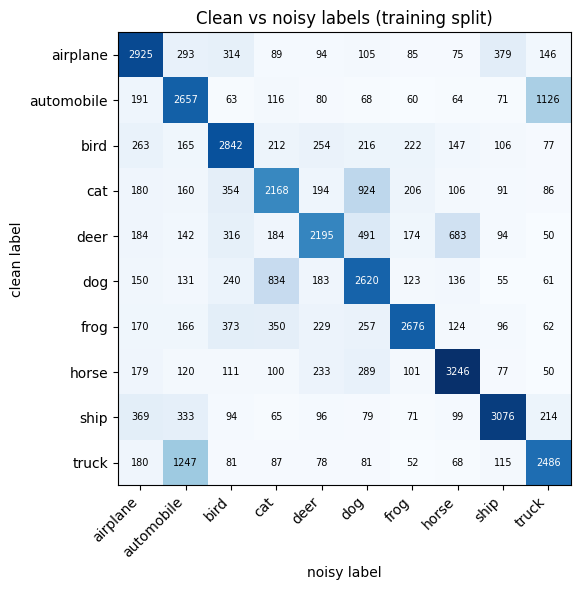

In [5]:
import matplotlib.pyplot as plt

c, n = CLEAN[TRAIN_IDX], NOISY[TRAIN_IDX]
wrong = int(np.sum(c != n))
print(f"Noise rate on the training split: {wrong / len(c):.4f} ({wrong} wrong labels)\n")

# Confusion matrix: rows = clean label, columns = noisy label
cm = pd.crosstab(pd.Series(c, name="clean"), pd.Series(n, name="noisy"))
cm.index = cm.columns = CLASSES
cm.to_csv(WORK / "confusion_matrix.csv")
display(cm)

# Class pairs (both directions together) causing the most wrong labels
m = cm.to_numpy()
pairs = sorted(((m[i, j] + m[j, i], f"{CLASSES[i]} <-> {CLASSES[j]}") for i in range(10) for j in range(i + 1, 10)), reverse=True)[:6]
top = pd.DataFrame(pairs, columns=["wrong labels", "pair"])
top["share"] = (top["wrong labels"] / wrong).round(3)
top["cumulative"] = top["share"].cumsum().round(3)
print(top.to_string(index=False))
print("\nNoise rate per class:", pd.Series(1 - np.diag(m) / m.sum(1), index=CLASSES).round(3).to_dict())

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(m, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, m[i, j], ha="center", va="center", fontsize=7, color="white" if m[i, j] > 2000 else "black")
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right"); ax.set_yticks(range(10), CLASSES)
ax.set_xlabel("noisy label"); ax.set_ylabel("clean label"); ax.set_title("Clean vs noisy labels (training split)")
plt.tight_layout(); plt.savefig(WORK / "confusion_matrix.png", dpi=150); plt.show()

Task 1 · Train the clean-label reference model (60 epochs)
Clean training labels are allowed only for this reference model.

In [6]:
hist_clean = train_run("t1_clean_ref", TRAIN_IDX, CLEAN[TRAIN_IDX],
                       epoch_hook=lambda m: {"val_acc_clean": round(accuracy(m, VAL_IDX, CLEAN), 4)})

[t1_clean_ref] already trained – loading saved history


Task 1 · Train the noisy-label CE model (60 epochs; also logs the Task 2 training dynamics)
Each epoch logs: train accuracy on correctly labeled and mislabeled images (against their given label), validation accuracy with noisy labels (used for early stopping) and with clean labels (measurement only).

In [7]:
is_correct = NOISY[TRAIN_IDX] == CLEAN[TRAIN_IDX]          # measurement only, never used for training

def dynamics_hook(model):
    pred = predict_probs(model, X[TRAIN_IDX]).argmax(1)    # unaugmented training images
    hit = pred == NOISY[TRAIN_IDX]
    return {"train_acc_correct": round(float(hit[is_correct].mean()), 4),
            "train_acc_mislabeled": round(float(hit[~is_correct].mean()), 4),
            "val_acc_clean": round(accuracy(model, VAL_IDX, CLEAN), 4)}

hist_noisy = train_run("t1_noisy_ce", TRAIN_IDX, NOISY[TRAIN_IDX], select_y=NOISY, epoch_hook=dynamics_hook)

[t1_noisy_ce] already trained – loading saved history


Task 1 · Evaluate both models at the final epoch and write test predictions

In [8]:
from check_format import check_pred_file

rows = []
for name in ["t1_clean_ref", "t1_noisy_ce"]:
    model = load_model(WORK / name / "final.pt")
    save_test_preds(model, f"{name}.csv")
    check_pred_file(str(PRED / f"{name}.csv"))             # raises an error if the format is wrong
    rows.append({"model": name,
                 "val acc (noisy labels)": round(accuracy(model, VAL_IDX, NOISY), 4),
                 "val acc (clean labels, measurement only)": round(accuracy(model, VAL_IDX, CLEAN), 4),
                 "prediction file": f"{name}.csv ✅"})
display(pd.DataFrame(rows))

,model,val acc (noisy labels),"val acc (clean labels, measurement only)",prediction file
0,t1_clean_ref,0.5896,0.9440,t1_clean_ref.csv ✅
1,t1_noisy_ce,0.4968,0.6914,t1_noisy_ce.csv ✅


Task 2 · Training dynamics of the noisy-label CE run (per epoch)

In [9]:
from check_format import check_dynamics

hist = pd.DataFrame(json.load(open(WORK / "t1_noisy_ce" / "history.json")))
dyn = hist.rename(columns={"val_acc": "val_acc_noisy"})[
    ["epoch", "train_acc_correct", "train_acc_mislabeled", "val_acc_noisy", "val_acc_clean"]]
dyn.to_csv(PRED / "t2_dynamics.csv", index=False)
check_dynamics(str(PRED / "t2_dynamics.csv"))              # raises an error if the format is wrong
print(f"t2_dynamics.csv ✅ ({len(dyn)} epochs)\n")
print(dyn[dyn.epoch % 5 == 0].to_string(index=False))

t2_dynamics.csv ✅ (60 epochs)

 epoch  train_acc_correct  train_acc_mislabeled  val_acc_noisy  val_acc_clean
     5             0.6030                0.1473         0.4164         0.5556
    10             0.6812                0.1118         0.4500         0.6194
    15             0.7186                0.1305         0.4754         0.6452
    20             0.7778                0.1196         0.5038         0.6968
    25             0.7866                0.1310         0.5030         0.7136
    30             0.8566                0.1298         0.5328         0.7678
    35             0.8281                0.1819         0.5326         0.7242
    40             0.9051                0.1767         0.5478         0.7782
    45             0.9106                0.2166         0.5272         0.7652
    50             0.9134                0.3358         0.5222         0.7320
    55             0.9554                0.5328         0.5078         0.7060
    60             0.9701        

Task 2 · When does memorization of wrong labels start?
Memorization start = first epoch where train accuracy on mislabeled images (against their wrong label) rises above its early plateau and stays above it. Early stopping uses noisy validation accuracy only.

Memorization starts at epoch 41 (mislabeled-train plateau 0.170, learning rate 0.0228)
Early-stop epoch (noisy val): 39  val_noisy=0.5502  val_clean=0.7850
Best clean-val epoch (measurement only): 41  val_clean=0.7870
Final epoch: train_acc_mislabeled=0.6554  val_clean=0.6914


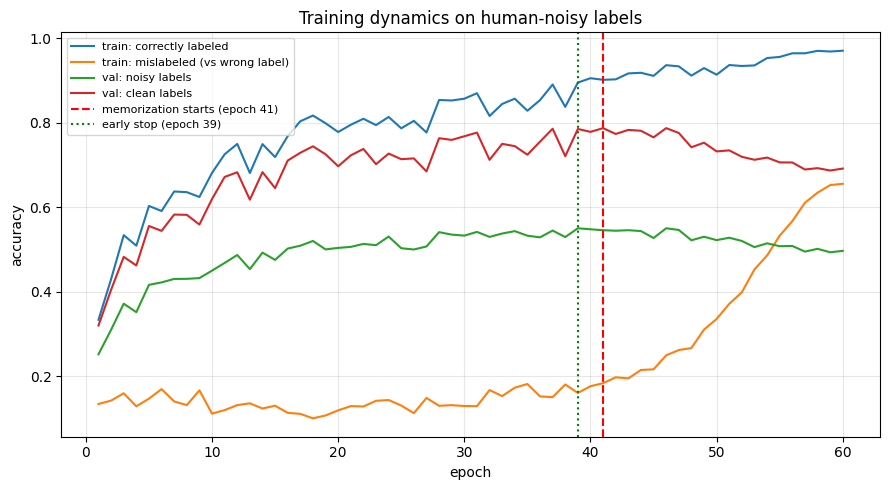

In [10]:
import matplotlib.pyplot as plt

# Plateau = highest mislabeled-train accuracy in the first half of training; memorization = stays above it from then on
plateau = dyn.train_acc_mislabeled.iloc[: len(dyn) // 2].max()
above = dyn.train_acc_mislabeled > plateau + 0.01
mem_epoch = int(dyn.epoch[above & above[::-1].cummin()[::-1]].iloc[0])

es = dyn.loc[dyn.val_acc_noisy.idxmax()]                  # early stop: best NOISY validation accuracy
es_epoch = int(es.epoch)
clean_peak = dyn.loc[dyn.val_acc_clean.idxmax()]          # measurement only
lr_at = lambda e: 0.1 * (1 + np.cos(np.pi * e / 60)) / 2  # cosine learning rate after epoch e

print(f"Memorization starts at epoch {mem_epoch} (mislabeled-train plateau {plateau:.3f}, learning rate {lr_at(mem_epoch):.4f})")
print(f"Early-stop epoch (noisy val): {es_epoch}  val_noisy={es.val_acc_noisy:.4f}  val_clean={es.val_acc_clean:.4f}")
print(f"Best clean-val epoch (measurement only): {int(clean_peak.epoch)}  val_clean={clean_peak.val_acc_clean:.4f}")
print(f"Final epoch: train_acc_mislabeled={dyn.train_acc_mislabeled.iloc[-1]:.4f}  val_clean={dyn.val_acc_clean.iloc[-1]:.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
for col, label in [("train_acc_correct", "train: correctly labeled"), ("train_acc_mislabeled", "train: mislabeled (vs wrong label)"),
                   ("val_acc_noisy", "val: noisy labels"), ("val_acc_clean", "val: clean labels")]:
    ax.plot(dyn.epoch, dyn[col], label=label)
ax.axvline(mem_epoch, color="red", ls="--", label=f"memorization starts (epoch {mem_epoch})")
ax.axvline(es_epoch, color="green", ls=":", label=f"early stop (epoch {es_epoch})")
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_title("Training dynamics on human-noisy labels")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(WORK / "t2_dynamics.png", dpi=150); plt.show()

Task 2 · Test predictions from the early-stopped model

In [11]:
from check_format import check_pred_file

es_model = load_model(WORK / "t1_noisy_ce" / "best.pt")   # checkpoint saved at the best noisy-val epoch
save_test_preds(es_model, "t2_early_stop.csv")
check_pred_file(str(PRED / "t2_early_stop.csv"))
T2 = {"memorization_start_epoch": mem_epoch, "early_stop_epoch": es_epoch,
      "val_acc_noisy_labels_at_early_stop": round(accuracy(es_model, VAL_IDX, NOISY), 4)}
json.dump(T2, open(WORK / "t2_summary.json", "w"), indent=2)
print(T2, "| val acc (clean, measurement only):", round(accuracy(es_model, VAL_IDX, CLEAN), 4))
print("t2_early_stop.csv ✅")

{'memorization_start_epoch': 41, 'early_stop_epoch': 39, 'val_acc_noisy_labels_at_early_stop': 0.5502} | val acc (clean, measurement only): 0.785
t2_early_stop.csv ✅


> Task 4's first method (ELR) is trained before Task 3 because the Task 3 noise scores average predictions from several noisy-label models, including ELR.

Task 4 · Method 1: Early-Learning Regularization (ELR, Liu et al., NeurIPS 2020)
Keeps a running average of each image's predictions (learned early, mostly correct) and adds λ·log(1 − ⟨p, t⟩), which stops the network from memorizing wrong labels later in training. λ = 3, β = 0.7 (published CIFAR-10 values). All other training settings are identical to the baseline.

In [12]:
def make_elr_loss(n, lam=3.0, beta=0.7):
    """Cross-entropy + ELR regularizer; keeps one running target per training image."""
    targets = torch.zeros(n, 10, device=DEV)
    def loss_fn(logits, y, pos):
        p = logits.float().softmax(1).clamp(1e-4, 1 - 1e-4)
        with torch.no_grad():                                 # update running targets (no gradient)
            targets[pos] = beta * targets[pos] + (1 - beta) * p / p.sum(1, keepdim=True)
        reg = torch.log(1 - (targets[pos] * p).sum(1)).mean()
        return F.cross_entropy(logits.float(), y) + lam * reg
    return loss_fn

clean_val_hook = lambda m: {"val_acc_clean": round(accuracy(m, VAL_IDX, CLEAN), 4)}   # measurement only

Task 4 · Train ELR on noisy labels (model selection: noisy validation accuracy)

In [13]:
hist_elr = train_run("t4_elr", TRAIN_IDX, NOISY[TRAIN_IDX], loss_fn=make_elr_loss(len(TRAIN_IDX)),
                     select_y=NOISY, epoch_hook=clean_val_hook)

[t4_elr] already trained – loading saved history


Task 5 · Train the CE baseline on synthetic labels (model selection: synthetic validation accuracy)

In [14]:
hist_ce_synth = train_run("t5_ce_synth", TRAIN_IDX, SYNTH[TRAIN_IDX], select_y=SYNTH, epoch_hook=clean_val_hook)

[t5_ce_synth] already trained – loading saved history


Task 5 · Train ELR on synthetic labels (model selection: synthetic validation accuracy)

In [15]:
hist_elr_synth = train_run("t5_elr_synth", TRAIN_IDX, SYNTH[TRAIN_IDX], loss_fn=make_elr_loss(len(TRAIN_IDX)),
                           select_y=SYNTH, epoch_hook=clean_val_hook)

[t5_elr_synth] already trained – loading saved history


Evaluate the new runs and write prediction files

,run,selection labels,best epoch,val acc (selection labels),"val acc (clean, measurement only)",file
0,t4_elr,noisy,59,0.5766,0.8506,t4_elr.csv
1,t5_ce_synth,synthetic,41,0.5020,0.8392,t5_baseline_synth.csv
2,t5_elr_synth,synthetic,57,0.5354,0.8994,-


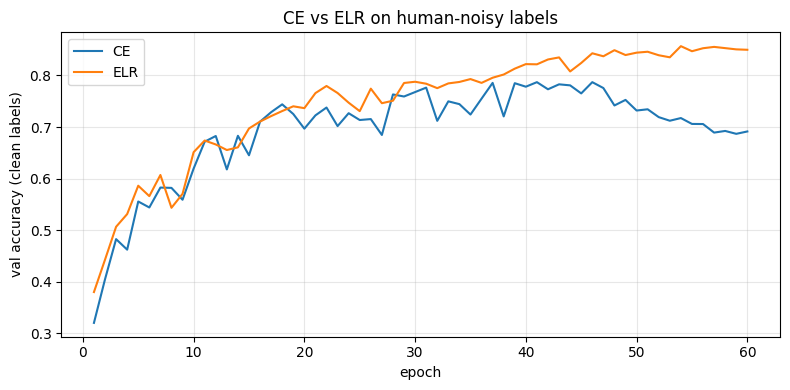

In [16]:
from check_format import check_pred_file

rows = []
for name, sel, sel_name, pred_file in [("t4_elr", NOISY, "noisy", "t4_elr.csv"),
                                       ("t5_ce_synth", SYNTH, "synthetic", "t5_baseline_synth.csv"),
                                       ("t5_elr_synth", SYNTH, "synthetic", None)]:   # t5_best_synth.csv is written after Task 4 picks the best method
    h = pd.DataFrame(json.load(open(WORK / name / "history.json")))
    model = load_model(WORK / name / "best.pt")
    if pred_file:
        save_test_preds(model, pred_file); check_pred_file(str(PRED / pred_file))
    rows.append({"run": name, "selection labels": sel_name, "best epoch": int(h.loc[h.val_acc.idxmax(), "epoch"]),
                 "val acc (selection labels)": round(accuracy(model, VAL_IDX, sel), 4),
                 "val acc (clean, measurement only)": round(accuracy(model, VAL_IDX, CLEAN), 4),
                 "file": pred_file or "-"})
display(pd.DataFrame(rows))

# Clean-label validation curves: CE vs ELR on human-noisy labels (measurement only, for the report)
ce, elr = (pd.DataFrame(json.load(open(WORK / r / "history.json"))) for r in ["t1_noisy_ce", "t4_elr"])
plt.figure(figsize=(8, 4))
plt.plot(ce.epoch, ce.val_acc_clean, label="CE"); plt.plot(elr.epoch, elr.val_acc_clean, label="ELR")
plt.xlabel("epoch"); plt.ylabel("val accuracy (clean labels)"); plt.title("CE vs ELR on human-noisy labels")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(WORK / "ce_vs_elr.png", dpi=150); plt.show()

Task 3 · Noise score for every training image
Score = 1 − P(given label), where P is the softmax averaged over two models trained on noisy labels (early-stopped CE and ELR) and over a horizontal flip. Two models that make different mistakes rank wrong labels better than either alone. Clean labels are not used to compute the scores.

In [17]:
def run_probs(run):
    """Softmax (with flip TTA) of a run's best checkpoint on all 50k training-set images."""
    return predict_probs(load_model(WORK / run / "best.pt"), X, tta=True)

PROBS = {"CE early-stopped": run_probs("t1_noisy_ce"), "ELR": run_probs("t4_elr")}
P_NOISY = np.mean(list(PROBS.values()), axis=0)                 # ensemble
score = 1 - P_NOISY[np.arange(len(NOISY)), NOISY]

scores_df = pd.DataFrame({"index": TRAIN_IDX, "score": score[TRAIN_IDX]})
scores_df.to_csv(PRED / "t3_noise_scores.csv", index=False)
assert len(scores_df) == 45000 and scores_df["index"].is_unique and np.isfinite(scores_df.score).all()
print("t3_noise_scores.csv ✅ (45,000 training images)")
print(scores_df.sort_values("score", ascending=False).head().to_string(index=False))

t3_noise_scores.csv ✅ (45,000 training images)
 index    score
 35998 0.998408
 18664 0.998310
 10475 0.998067
 28969 0.997976
 44675 0.997906


Task 3 · Own check of the scores against clean labels (measurement only, nothing is selected with it)
AUROC and precision@k (k = true number of mislabeled training images) for each model and the ensemble, plus which kinds of wrong labels are hardest to detect (failure mode).

In [19]:
from sklearn.metrics import roc_auc_score

y_tr, wrong = NOISY[TRAIN_IDX], NOISY[TRAIN_IDX] != CLEAN[TRAIN_IDX]
k = int(wrong.sum())

def detection(s):
    """AUROC, precision@k, and a mask of the top-k scored images."""
    top = np.zeros(len(s), bool); top[np.argsort(-s)[:k]] = True
    return roc_auc_score(wrong, s), wrong[top].mean(), top

rows = []
for name, P in {**PROBS, "Ensemble (submitted)": P_NOISY}.items():
    auc, prec, top = detection(1 - P[TRAIN_IDX, y_tr])
    rows.append({"signal": name, "AUROC": round(auc, 4), f"precision@{k}": round(prec, 4)})
display(pd.DataFrame(rows))

# Failure mode: detection recall for the most common wrong-label types (clean -> given)
_, _, top = detection(score[TRAIN_IDX])
fm = pd.DataFrame({"clean": [CLASSES[i] for i in CLEAN[TRAIN_IDX][wrong]],
                   "given": [CLASSES[i] for i in y_tr[wrong]], "detected": top[wrong]})
fm = fm.groupby(["clean", "given"])["detected"].agg(count="size", recall="mean").sort_values("count", ascending=False)
print(f"Overall recall of wrong labels in top-k: {top[wrong].mean():.3f}")
print(f"Correct labels wrongly flagged in top-k: {(top & ~wrong).sum()}")
display(fm.head(8).round(3))

,signal,AUROC,precision@18109
0,CE early-stopped,0.9439,0.8443
1,ELR,0.9636,0.8844
2,Ensemble (submitted),0.9617,0.8765


Overall recall of wrong labels in top-k: 0.877
Correct labels wrongly flagged in top-k: 2236


count  recall
clean      given                    
truck      automobile   1247   0.779
automobile truck        1126   0.935
cat        dog           924   0.369
dog        cat           834   0.924
deer       horse         683   0.631
           dog           491   0.851
airplane   ship          379   0.755
frog       bird          373   0.936

Task 3 · Relabel files for the Task 4 relabel method
Rule (fixed in advance, not tuned): keep the given label if the ensemble agrees; replace it with the ensemble's class if the ensemble disagrees with confidence ≥ 0.6; otherwise drop the image. The same rule is applied to the synthetic labels using the two synthetic-label models, for Task 5.

In [20]:
def relabel_targets(P, y, tau=0.6):
    """New training labels from ensemble probabilities P; -1 means drop the image."""
    tr = TRAIN_IDX
    pred, conf = P.argmax(1), P.max(1)
    t = np.full(len(y), -1)
    agree = pred[tr] == y[tr]
    t[tr] = np.where(agree, y[tr], np.where(conf[tr] >= tau, pred[tr], -1))
    return t

P_SYNTH = np.mean([run_probs("t5_ce_synth"), run_probs("t5_elr_synth")], axis=0)
TARGETS = {"noisy": relabel_targets(P_NOISY, NOISY), "synthetic": relabel_targets(P_SYNTH, SYNTH)}

rows = []
for name, y in [("noisy", NOISY), ("synthetic", SYNTH)]:
    t = TARGETS[name]; np.save(WORK / f"targets_{name}.npy", t)
    tr = TRAIN_IDX; kept = t[tr] >= 0; changed = kept & (t[tr] != y[tr])
    s = 1 - (P_NOISY if name == "noisy" else P_SYNTH)[tr, y[tr]]
    rows.append({"labels": name, "kept as is": int((kept & ~changed).sum()), "relabelled": int(changed.sum()),
                 "dropped": int((~kept).sum()),
                 "label accuracy before (measurement)": round(float((y[tr] == CLEAN[tr]).mean()), 4),
                 "label accuracy after, kept images (measurement)": round(float((t[tr][kept] == CLEAN[tr][kept]).mean()), 4),
                 "noise-score AUROC (measurement)": round(roc_auc_score(y[tr] != CLEAN[tr], s), 4)})
display(pd.DataFrame(rows))

,labels,kept as is,relabelled,dropped,label accuracy before (measurement),"label accuracy after, kept images (measurement)",noise-score AUROC (measurement)
0,noisy,29083,12491,3426,0.5976,0.8874,0.9617
1,synthetic,26921,14929,3150,0.5990,0.9557,0.9889


Task 4 · Method 2: relabel with Task 3 scores, then retrain with ELR
Train on the relabelled set from Task 3 (dropped images removed) with the same ELR loss and training settings. Model selection still uses the original noisy validation labels.

In [21]:
targets_noisy = np.load(WORK / "targets_noisy.npy")
idx_rl = TRAIN_IDX[targets_noisy[TRAIN_IDX] >= 0]            # images kept after relabelling
print(f"Training on {len(idx_rl)} images")
hist_rl = train_run("t4_relabel_elr", idx_rl, targets_noisy[idx_rl], loss_fn=make_elr_loss(len(idx_rl)),
                    select_y=NOISY, epoch_hook=clean_val_hook)

Training on 41574 images
[t4_relabel_elr] epoch=1  loss=1.4683  val_acc=0.3246  val_acc_clean=0.4216  (14s)
[t4_relabel_elr] epoch=2  loss=0.4865  val_acc=0.3972  val_acc_clean=0.5188  (13s)
[t4_relabel_elr] epoch=3  loss=-0.3241  val_acc=0.4508  val_acc_clean=0.6112  (13s)
[t4_relabel_elr] epoch=4  loss=-1.0997  val_acc=0.468  val_acc_clean=0.6496  (12s)
[t4_relabel_elr] epoch=5  loss=-1.8401  val_acc=0.4596  val_acc_clean=0.6532  (12s)
[t4_relabel_elr] epoch=6  loss=-2.6069  val_acc=0.4832  val_acc_clean=0.6694  (12s)
[t4_relabel_elr] epoch=7  loss=-3.3663  val_acc=0.5138  val_acc_clean=0.73  (12s)
[t4_relabel_elr] epoch=8  loss=-4.0678  val_acc=0.5114  val_acc_clean=0.723  (12s)
[t4_relabel_elr] epoch=9  loss=-4.7353  val_acc=0.5256  val_acc_clean=0.738  (12s)
[t4_relabel_elr] epoch=10  loss=-5.4327  val_acc=0.5102  val_acc_clean=0.7488  (12s)
[t4_relabel_elr] epoch=11  loss=-6.0982  val_acc=0.5008  val_acc_clean=0.711  (12s)
[t4_relabel_elr] epoch=12  loss=-6.7383  val_acc=0.5046  

Task 5 · Same method on synthetic labels (relabel file built from the synthetic-label models; selection: synthetic validation accuracy)

In [22]:
targets_synth = np.load(WORK / "targets_synthetic.npy")
idx_rs = TRAIN_IDX[targets_synth[TRAIN_IDX] >= 0]
print(f"Training on {len(idx_rs)} images")
hist_rs = train_run("t5_relabel_elr_synth", idx_rs, targets_synth[idx_rs], loss_fn=make_elr_loss(len(idx_rs)),
                    select_y=SYNTH, epoch_hook=clean_val_hook)

Training on 41850 images
[t5_relabel_elr_synth] epoch=1  loss=1.6258  val_acc=0.2718  val_acc_clean=0.4186  (13s)
[t5_relabel_elr_synth] epoch=2  loss=0.7709  val_acc=0.3036  val_acc_clean=0.464  (13s)
[t5_relabel_elr_synth] epoch=3  loss=-0.038  val_acc=0.3812  val_acc_clean=0.6078  (13s)
[t5_relabel_elr_synth] epoch=4  loss=-0.8182  val_acc=0.4016  val_acc_clean=0.6606  (12s)
[t5_relabel_elr_synth] epoch=5  loss=-1.5595  val_acc=0.4244  val_acc_clean=0.6964  (12s)
[t5_relabel_elr_synth] epoch=6  loss=-2.3228  val_acc=0.3834  val_acc_clean=0.6106  (12s)
[t5_relabel_elr_synth] epoch=7  loss=-3.0527  val_acc=0.4618  val_acc_clean=0.765  (12s)
[t5_relabel_elr_synth] epoch=8  loss=-3.7654  val_acc=0.4186  val_acc_clean=0.6866  (12s)
[t5_relabel_elr_synth] epoch=9  loss=-4.4734  val_acc=0.4648  val_acc_clean=0.7668  (13s)
[t5_relabel_elr_synth] epoch=10  loss=-5.1513  val_acc=0.4616  val_acc_clean=0.7648  (12s)
[t5_relabel_elr_synth] epoch=11  loss=-5.8143  val_acc=0.4486  val_acc_clean=0.

Task 4 + 5 · Compare methods, pick the best by noisy validation accuracy, write prediction files
The best Task 4 method is the one with the highest noisy validation accuracy. Its synthetic-label run gives t5_best_synth.csv.

In [23]:
from check_format import check_pred_file

METHODS = {"elr": ("t4_elr", "t5_elr_synth"), "relabel_elr": ("t4_relabel_elr", "t5_relabel_elr_synth")}
rows = []
for method, (run, synth_run) in METHODS.items():
    m, ms = load_model(WORK / run / "best.pt"), load_model(WORK / synth_run / "best.pt")
    save_test_preds(m, f"t4_{method}.csv"); check_pred_file(str(PRED / f"t4_{method}.csv"))
    rows.append({"method": method, "file": f"t4_{method}.csv",
                 "val acc (noisy)": round(accuracy(m, VAL_IDX, NOISY), 4),
                 "val acc (clean, measurement)": round(accuracy(m, VAL_IDX, CLEAN), 4),
                 "synthetic: val acc (synthetic)": round(accuracy(ms, VAL_IDX, SYNTH), 4),
                 "synthetic: val acc (clean, measurement)": round(accuracy(ms, VAL_IDX, CLEAN), 4)})
res = pd.DataFrame(rows)
display(res)

best = res.loc[res["val acc (noisy)"].idxmax()]                  # selection uses noisy labels only
save_test_preds(load_model(WORK / METHODS[best.method][1] / "best.pt"), "t5_best_synth.csv")
check_pred_file(str(PRED / "t5_best_synth.csv"))

base_synth = load_model(WORK / "t5_ce_synth" / "best.pt")
T45 = {"methods": [{"name": r.method, "file": r.file, "val_acc_noisy_labels": r["val acc (noisy)"]} for _, r in res.iterrows()],
       "best_method": best.method,
       "val_acc_synthetic_labels__baseline": round(accuracy(base_synth, VAL_IDX, SYNTH), 4),
       "val_acc_synthetic_labels__best_method": best["synthetic: val acc (synthetic)"]}
json.dump(T45, open(WORK / "t45_summary.json", "w"), indent=2)
print("Best Task 4 method:", best.method, "| t5_best_synth.csv ✅")
print(json.dumps(T45, indent=2))

,method,file,val acc (noisy),"val acc (clean, measurement)",synthetic: val acc (synthetic),"synthetic: val acc (clean, measurement)"
0,elr,t4_elr.csv,0.5766,0.8506,0.5354,0.8994
1,relabel_elr,t4_relabel_elr.csv,0.5796,0.8614,0.5376,0.9070


Best Task 4 method: relabel_elr | t5_best_synth.csv ✅
{
  "methods": [
    {
      "name": "elr",
      "file": "t4_elr.csv",
      "val_acc_noisy_labels": 0.5766
    },
    {
      "name": "relabel_elr",
      "file": "t4_relabel_elr.csv",
      "val_acc_noisy_labels": 0.5796
    }
  ],
  "best_method": "relabel_elr",
  "val_acc_synthetic_labels__baseline": 0.502,
  "val_acc_synthetic_labels__best_method": 0.5376
}


## Submission · Fill results.json from the provided template

In [24]:
res = json.load(open(find("results_template.json")))
res.update({"name": "Mehak", "roll_no": "23B4210", "seed": 42})
res["training_setup"] = {"optimizer": "SGD(lr=0.1, momentum=0.9, weight_decay=5e-4)",
                         "learning_rate_schedule": "CosineAnnealingLR(T_max=60), stepped per epoch",
                         "batch_size": 128, "epochs": 60,
                         "augmentation": "RandomCrop(32, padding=4) + RandomHorizontalFlip",
                         "gpu_used": torch.cuda.get_device_name(0)}
res["task1"] = {"noise_rate": round(float((NOISY[TRAIN_IDX] != CLEAN[TRAIN_IDX]).mean()), 4),
                "val_acc_noisy_labels__clean_ref_model": round(accuracy(load_model(WORK / "t1_clean_ref" / "final.pt"), VAL_IDX, NOISY), 4),
                "val_acc_noisy_labels__noisy_ce_model": round(accuracy(load_model(WORK / "t1_noisy_ce" / "final.pt"), VAL_IDX, NOISY), 4)}
res["task2"] = json.load(open(WORK / "t2_summary.json"))
res["task3"] = {"method": "1 - P(given noisy label), P = softmax averaged over early-stopped CE and ELR models "
                          "trained on noisy labels, with horizontal-flip test-time augmentation"}
t45 = json.load(open(WORK / "t45_summary.json"))
res["task4"] = {"methods": t45["methods"], "best_method": t45["best_method"]}
res["task5"] = {k: t45[k] for k in ["val_acc_synthetic_labels__baseline", "val_acc_synthetic_labels__best_method"]}
json.dump(res, open(SUB / "results.json", "w"), indent=2)
print(json.dumps(res, indent=2))

{
  "name": "Mehak",
  "roll_no": "23B4210",
  "seed": 42,
  "training_setup": {
    "optimizer": "SGD(lr=0.1, momentum=0.9, weight_decay=5e-4)",
    "learning_rate_schedule": "CosineAnnealingLR(T_max=60), stepped per epoch",
    "batch_size": 128,
    "epochs": 60,
    "augmentation": "RandomCrop(32, padding=4) + RandomHorizontalFlip",
    "gpu_used": "Tesla T4"
  },
  "task1": {
    "noise_rate": 0.4024,
    "val_acc_noisy_labels__clean_ref_model": 0.5896,
    "val_acc_noisy_labels__noisy_ce_model": 0.4968
  },
  "task2": {
    "memorization_start_epoch": 41,
    "early_stop_epoch": 39,
    "val_acc_noisy_labels_at_early_stop": 0.5502
  },
  "task3": {
    "method": "1 - P(given noisy label), P = softmax averaged over early-stopped CE and ELR models trained on noisy labels, with horizontal-flip test-time augmentation"
  },
  "task4": {
    "methods": [
      {
        "name": "elr",
        "file": "t4_elr.csv",
        "val_acc_noisy_labels": 0.5766
      },
      {
        "name": 

Submission · Report (Q1–Q5, ≤ 100 words each)

In [25]:
report = """# CV Bootcamp Report: Learning from Noisy Labels (CIFAR-10N)

## Q1
Noise is highly structured. Four confusable pairs cause 32% of the 18,109 wrong training labels: automobile↔truck (2,373; 13.1%), cat↔dog (1,758; 9.7%), deer↔horse (916; 5.1%, mostly deer→horse) and airplane↔ship (748; 4.1%). Deer→dog and bird↔frog add another 7%. Cat and deer are the noisiest classes (51% wrong) and horse the cleanest (28%). The remaining errors are spread thinly (50–400 per cell). In contrast, symmetric synthetic noise puts 168–232 images in every off-diagonal cell.

## Q2
Memorization starts at epoch 41. Training accuracy on mislabeled images, measured against their wrong labels, stays at 0.10–0.17 for epochs 1–40, then climbs to 0.66 by epoch 60. Over the same period clean-label validation accuracy falls from 0.79 to 0.69 and noisy-label validation from 0.55 to 0.50. The onset coincides with the cosine learning rate falling to about 0.023, when small steps let the network fit individual wrong labels. Noisy validation selects epoch 39 (clean accuracy 0.785), just before the onset.

## Q3
The best single signal was 1 − P(given label) from the ELR model (AUROC 0.964, precision@k 0.884). The submitted score, fixed in advance, averages early-stopped CE and ELR with flip augmentation (AUROC 0.962, precision@k 0.877), versus 0.944 / 0.844 for CE alone. Failure mode: systematic human confusions. Only 37% of cat→dog errors reach the top-k, versus 92% of dog→cat and 88% overall, because the network learns the annotators' confusion and trusts the wrong label. Also, 2,236 correct but ambiguous images are flagged.

## Q4
Relabel + ELR was best: noisy validation 0.580 (clean, measured only, 0.861), ahead of ELR alone (0.577 / 0.851) and early-stopped CE (0.550 / 0.785). ELR keeps a running average of each image's early, mostly correct predictions and penalizes moving away from them, so wrong labels stop pulling the network once the learning rate decays: CE's clean accuracy falls from 0.79 to 0.69 after epoch 41, while ELR keeps rising. Relabeling with Task 3 scores raised kept-label accuracy from 60% to 89% (measured only), leaving fewer wrong labels to resist.

## Q5
The ranking did not change: relabel + ELR (synthetic validation 0.538; clean, measured only, 0.907) beat ELR (0.535; 0.899) and CE (0.502; 0.839), as on human noise. All methods reach higher clean accuracy under synthetic noise, and its errors are easier to find (detection AUROC 0.989 vs 0.962; relabelled labels 96% vs 89% correct). Symmetric noise is random, so wrong labels share no visual pattern and the network learns true classes first. Human noise sits in confusable pairs such as cat/dog, which the network itself confuses, so early predictions and relabels inherit part of it.
"""
(SUB / "report.md").write_text(report)
for q in report.split("## Q")[1:]:
    print(f"Q{q[0]}: {len(q[1:].split())} words")

Q1: 71 words
Q2: 81 words
Q3: 82 words
Q4: 90 words
Q5: 95 words


Submission · README with exact reproduction steps

In [26]:
readme = """# CV Bootcamp: Learning from Noisy Labels (CIFAR-10N)

## How to reproduce
1. Put the provided files in Google Drive at `MyDrive/cv_bootcamp/`.
2. Open `CV_Bootcamp.ipynb` (this folder) in Google Colab with a T4 GPU.
3. Run `Runtime → Run all`. Each 60-epoch run takes about 15–25 minutes. Finished runs are saved in
   `MyDrive/cv_bootcamp/work/` and skipped on re-run.

## Notebook order
- Step 0: mount Drive, verify files, load data, shared training setup (organizer ResNet-18 from `model.py`).
- Task 1: noise rate and confusion matrix; clean-reference and noisy CE models (final epoch).
- Task 2: per-epoch dynamics, memorization epoch, early-stopped predictions (noisy validation only).
- Task 4 method 1 (ELR) and Task 5 runs on synthetic labels: trained before Task 3, whose ensemble uses them.
- Task 3: ensemble noise scores (early-stopped CE + ELR, flip TTA), own check with clean labels, relabel files.
- Task 4 method 2 (relabel + ELR) and its synthetic-label run; best method chosen by noisy validation accuracy.
- Submission: results.json, report.md, format check, zip.

## Training setup (identical for all runs)
Seed 42; SGD lr 0.1, momentum 0.9, weight decay 5e-4; cosine schedule; 60 epochs; batch 128;
RandomCrop(32, padding=4) + horizontal flip (on GPU); mixed precision.
Clean labels are used only for the Task 1 reference model and for measurements.
Model selection: noisy validation labels (Tasks 1-4), synthetic validation labels (Task 5).
"""
(CODE / "README.md").write_text(readme)
print("README.md ✅")

README.md ✅


Submission · Copy notebook, run the format checker, build the zip

In [27]:
import subprocess
NB_NAME = "CV_Bootcamp.ipynb"
nb = next((p for p in Path("/content/drive/MyDrive").rglob(NB_NAME) if "submission" not in p.parts), None)
assert nb is not None, f"{NB_NAME} not found in Drive – check the name"
shutil.copy2(nb, CODE / NB_NAME)
shutil.rmtree(CODE / "__pycache__", ignore_errors=True)

zip_base = BASE / "23B4210_cv_bootcamp"
shutil.make_archive(str(zip_base), "zip", root_dir=SUB)
out = subprocess.run([sys.executable, "check_format.py", f"{zip_base}.zip"], cwd=CODE, capture_output=True, text=True)
print(out.stdout[-3000:], out.stderr[-1000:])
print("Zip ready:", f"{zip_base}.zip")


File check
------------------------------------------------------------
  t1_clean_ref.csv           OK
  t1_noisy_ce.csv            OK
  t2_dynamics.csv            OK
  t2_early_stop.csv          OK
  t3_noise_scores.csv        OK
  t4_elr.csv                 OK
  t4_relabel_elr.csv         OK
  t5_baseline_synth.csv      OK
  t5_best_synth.csv          OK

Task completeness (1.0 = all files valid)
------------------------------------------------------------
  task1: 1.00
  task2: 1.00
  task3: 1.00
  task4: 1.00
  task5: 1.00

All good.
 
Zip ready: /content/drive/MyDrive/cv_bootcamp/23B4210_cv_bootcamp.zip


In [28]:
import zipfile
print("\n".join(sorted(zipfile.ZipFile(BASE / "23B4210_cv_bootcamp.zip").namelist())))

checkpoints/
code/
code/CV_Bootcamp.ipynb
code/README.md
code/check_format.py
code/data/
code/data/train_idx.txt
code/model.py
predictions/
predictions/t1_clean_ref.csv
predictions/t1_noisy_ce.csv
predictions/t2_dynamics.csv
predictions/t2_early_stop.csv
predictions/t3_noise_scores.csv
predictions/t4_elr.csv
predictions/t4_relabel_elr.csv
predictions/t5_baseline_synth.csv
predictions/t5_best_synth.csv
report.md
results.json


In [29]:
import zipfile, subprocess
ck = SUB / "checkpoints"
if ck.exists() and not any(ck.iterdir()):
    ck.rmdir(); print("removed empty checkpoints/")

zip_base = BASE / "23B4210_cv_bootcamp"
shutil.make_archive(str(zip_base), "zip", root_dir=SUB)
out = subprocess.run([sys.executable, "check_format.py", f"{zip_base}.zip"], cwd=CODE, capture_output=True, text=True)
print(out.stdout[-400:])
print("\n".join(sorted(zipfile.ZipFile(f"{zip_base}.zip").namelist())))

removed empty checkpoints/
mics.csv            OK
  t2_early_stop.csv          OK
  t3_noise_scores.csv        OK
  t4_elr.csv                 OK
  t4_relabel_elr.csv         OK
  t5_baseline_synth.csv      OK
  t5_best_synth.csv          OK

Task completeness (1.0 = all files valid)
------------------------------------------------------------
  task1: 1.00
  task2: 1.00
  task3: 1.00
  task4: 1.00
  task5: 1.00

All good.

code/
code/CV_Bootcamp.ipynb
code/README.md
code/check_format.py
code/data/
code/data/train_idx.txt
code/model.py
predictions/
predictions/t1_clean_ref.csv
predictions/t1_noisy_ce.csv
predictions/t2_dynamics.csv
predictions/t2_early_stop.csv
predictions/t3_noise_scores.csv
predictions/t4_elr.csv
predictions/t4_relabel_elr.csv
predictions/t5_baseline_synth.csv
predictions/t5_best_synth.csv
report.md
results.json


In [30]:
import zipfile
print("\n".join(sorted(zipfile.ZipFile(BASE / "23B4210_cv_bootcamp.zip").namelist())))

code/
code/CV_Bootcamp.ipynb
code/README.md
code/check_format.py
code/data/
code/data/train_idx.txt
code/model.py
predictions/
predictions/t1_clean_ref.csv
predictions/t1_noisy_ce.csv
predictions/t2_dynamics.csv
predictions/t2_early_stop.csv
predictions/t3_noise_scores.csv
predictions/t4_elr.csv
predictions/t4_relabel_elr.csv
predictions/t5_baseline_synth.csv
predictions/t5_best_synth.csv
report.md
results.json
